In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [2]:
df=pd.read_csv("thyroid_dataset.csv")

In [3]:
df.head()

,Age,Sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,goitre,tumor,hypopituitary,psych,TSH,T3_measured,TT4_measured,T4U_measured,FTI_measured,Outlier_label
0,0.45,1,0,0,0,0,0,0,0,0,...,0,0,0,0,61.0,6.0,23.0,87.0,26.0,o
1,0.61,0,0,0,0,1,0,0,0,0,...,0,0,0,0,29.0,15.0,61.0,96.0,64.0,o
2,0.16,0,1,0,0,0,0,0,0,0,...,0,1,0,0,29.0,19.0,58.0,103.0,56.0,o
3,0.85,0,0,0,0,0,0,0,0,0,...,0,0,0,0,114.0,3.0,24.0,61.0,39.0,o
4,0.75,1,0,0,0,0,0,0,0,0,...,0,0,0,0,49.0,3.0,5.0,116.0,4.0,o


In [4]:
df.shape

(6916, 22)

In [6]:
X=df.drop("Outlier_label",axis=1)
y=df["Outlier_label"]

In [7]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

In [8]:
X_scaled

array([[-2.34449113e-02,  1.50050924e+00, -3.94405319e-01, ...,
        -1.40951598e+00, -3.74590514e-02, -1.25859776e+00],
       [ 2.40791602e-03, -6.66440415e-01, -3.94405319e-01, ...,
        -6.57814578e-01,  2.27969782e-01, -5.68029663e-01],
       [-7.03031607e-02, -6.66440415e-01,  2.53546276e+00, ...,
        -7.17159426e-01,  4.34414431e-01, -7.13412420e-01],
       ...,
       [-2.99081181e-02, -6.66440415e-01, -3.94405319e-01, ...,
         6.08208844e-01,  7.58827450e-01,  2.49748343e-01],
       [ 7.25532113e-03,  1.50050924e+00, -3.94405319e-01, ...,
         2.32358141e-01, -7.96695877e-03,  4.67822478e-01],
       [-2.18291096e-02, -6.66440415e-01, -3.94405319e-01, ...,
        -2.48028670e-02,  8.05093192e-02,  1.22538431e-01]],
      shape=(6916, 21))

In [13]:
from sklearn.ensemble import IsolationForest
iso_forest = IsolationForest(n_estimators=200,contamination='auto', random_state=42)
labels=iso_forest.fit_predict(X_scaled)

In [14]:
labels

array([ 1,  1, -1, ...,  1,  1,  1], shape=(6916,))

In [15]:
from sklearn.decomposition import PCA

# 3. Initialize and fit PCA
pca = PCA(n_components=2) # Reduce from 3 features to 2 components
X_pca = pca.fit_transform(X_scaled)

# 4. View properties
print("Transformed Shape:", X_pca.shape)
print("Variance explained by each component:", pca.explained_variance_ratio_)

Transformed Shape: (6916, 2)
Variance explained by each component: [0.07658851 0.06678657]


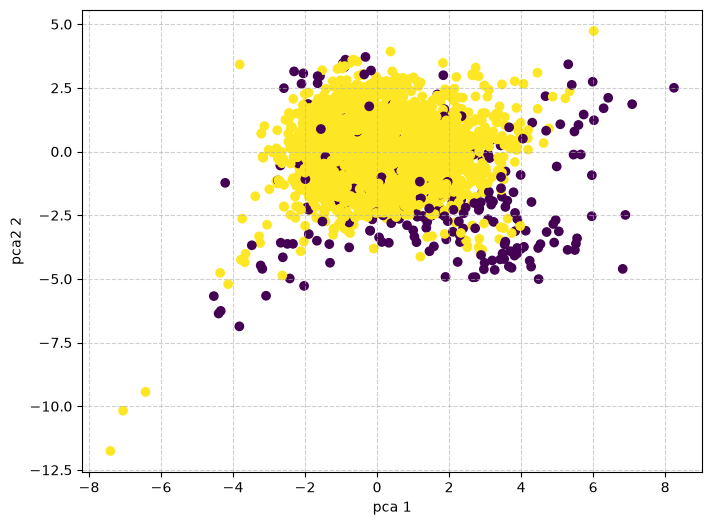

In [21]:

# 5. Plot the results
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels)


plt.xlabel("pca 1")
plt.ylabel("pca2 2")

plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [22]:
# Local outlier factor
# LOF


In [27]:
from sklearn.neighbors import LocalOutlierFactor
neighbs = LocalOutlierFactor()

labels=neighbs.fit_predict(X_scaled)

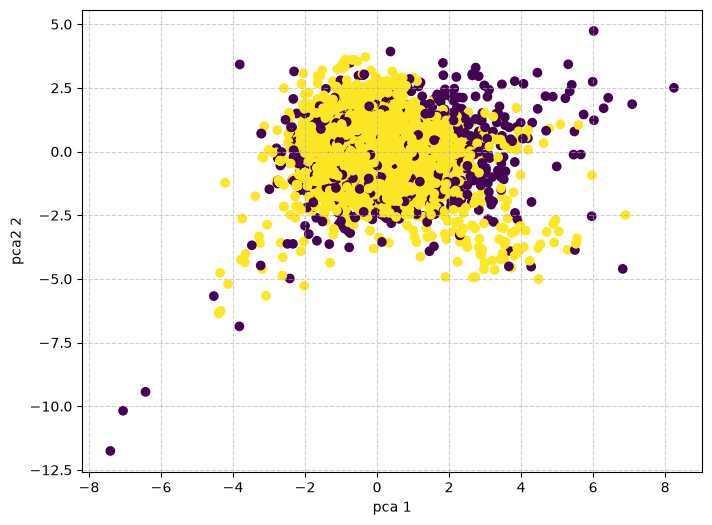

In [28]:

# 5. Plot the results
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels)


plt.xlabel("pca 1")
plt.ylabel("pca2 2")

plt.grid(True, linestyle='--', alpha=0.6)
plt.show()